#Task1: From Matplotlib to Seaborn

### Q1:

**ما الفرق بين Matplotlib و Seaborn ?**

- Matplotlib: مكتبة نستخدمها لإنشاء الرسومات البيانية والتحكم في تفاصيلها مثل الألوان والعناوين.

- Seaborn: مكتبة مبنية فوقها
وتسهل إنشاء رسومات إحصائية بشكل أجمل وبكود
أقل.

**لماذا نتعلم الاثنين؟**

 لأن كل مكتبة لها استخداماتها، ويمكن استخدامهما معًا للحصول على نتائج أفضل.

### Q2:
**ما وظيفة الـ hue?**

أعطِ مثالًا من داتا تعرفها: ماذا ستلوّن به؟ وماذا ستكتشف؟

hue: نستخدمه لتقسيم البيانات إلى مجموعات مختلفة باستخدام الألوان، بحيث نقدر نقارن بينها داخل نفس الرسمة.

مثال: بيانات القروض

ممكن نستخدم

hue="Loan_Status"

لتلوين البيانات حسب حالة
القرض
- لون للقروض المقبولة
- لون للقروض المرفوضة

وبكذا نقدر نلاحظ الاختلافات بين المجموعتين
بسهولة.

### Q3:
**فيsns.barplot يظهر فوق كل عمود خط أسود صغير. ماذا يعني؟**

الخط الأسود الصغير يمثل فترة الثقة (Confidence Interval).

وهو مهم لأنه يساعدنا نعرف إذا كان الفرق بين الأعمدة واضحًا، أو أن هناك احتمالًا لعدم وجود فرق حقيقي بينها.

### Q4:

**في boxplot:
 ماذا يمثل الخط داخل الصندوق؟
 ماذا تمثل حدود الصندوق؟
ماذا تمثل النقاط المنفصلة؟
 اربطيها بما تعلمتيه عن IQR الأسبوع الماضي.**

 الخط اللي داخل الصندوق يمثل الوسيط

 وحدود الصندوق توضح الربع الأول والثالث (Q1 , Q3)

 أما النقاط اللي تكون بعيدة عن الصندوق فهي القيم الشاذة

  والـ IQR
  
  هو الفرق بين الربع الثالث والأول، ونستخدمه عشان نعرف مدى انتشار البيانات ونحدد outliers

#Task2: بقشيش المطعم

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

tips = sns.load_dataset("tips")

tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### 1.histplot:
 أتوقع أن فواتير العشاء تكون أعلى من فواتير الغداء لأن غالبا الناس تطلب أكثر في العشاء

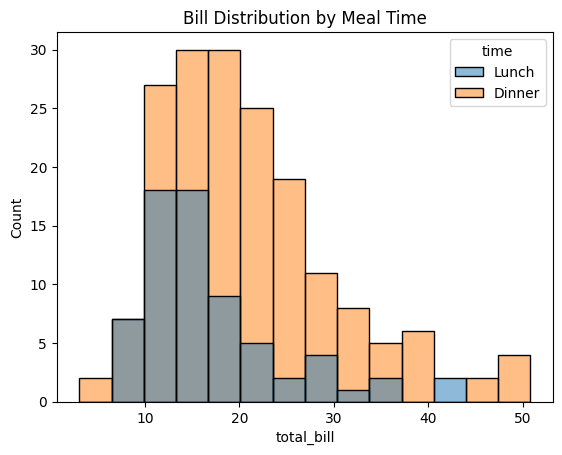

In [2]:
sns.histplot(data=tips, x="total_bill", hue="time")
plt.title("Bill Distribution by Meal Time")
plt.show()

من الرسم لاحظت أن فواتير العشاء غالبًا أعلى من فواتير الغداء، حيث وصلت بعض فواتير العشاء إلى حوالي 50 بينما أغلب فواتير الغداء كانت أقل من 20

 وهذا يتفق مع توقعي.

### 2. boxplot:
 أتوقع أن يكون احد ايام الويكند أعلى من باقي الأيام في وسيط البقشيش، لأن المطاعم غالبًا تكون أكثر ازدحامًا.

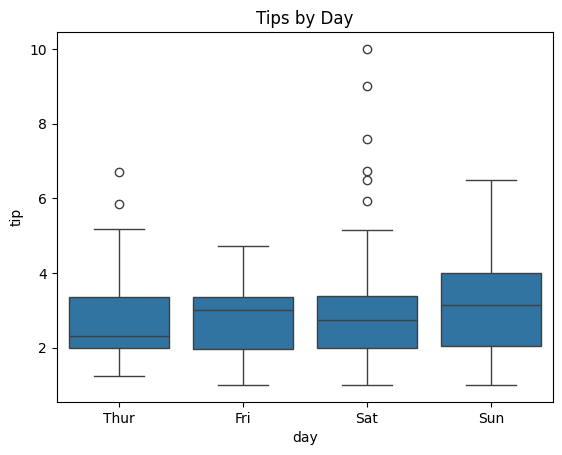

In [3]:
sns.boxplot(data=tips, x="day", y="tip")
plt.title("Tips by Day")
plt.show()

من الرسم لاحظت أن يوم الأحد عنده أعلى وسيط للبقشيش بحوالي 3.1، بينما يوم السبت فيه أكبر عدد من القيم الشاذة.

توقعي كان خاطئ لاني توقعت اذا زاد عدد الزبائن ممكن يزيد البقشيش.

### 3. countplot:

 أتوقع أن عدد الفواتير يكون متقارب بين المدخنين وغير المدخنين، لأن التدخين ما له علاقة مباشرة بعدد الفواتير، وممكن أي شخص يكون مدخن أو غير مدخن ويطلب بشكل عادي.

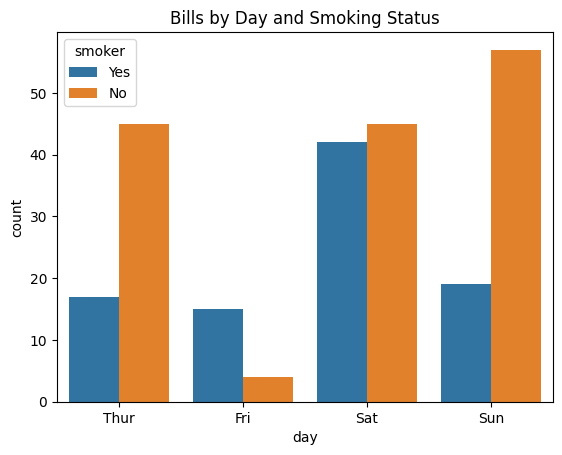

In [4]:
sns.countplot(data=tips, x="day", hue="smoker")
plt.title("Bills by Day and Smoking Status")
plt.show()

لاحظت أن عدد فواتير غير المدخنين كان أعلى في أغلب الأيام.

خصوصًا يوم الأحد بحوالي 57 فاتورة مقابل 19 للمدخنين.

 لكن يوم الجمعة كان العكس، ويوم السبت كانت الأعداد متقاربة.

  لذلك توقعي ما كان صحيح تمامًا.

### 4. scatterplot:
 أتوقع أن يكون فيه ارتباط بين قيمة الفاتورة والبقشيش، لكن مو شرط كلما زادت الفاتورة زاد البقشيش، لأن ممكن شخص تكون فاتورته عالية ويعطي بقشيش قليل أو ما يعطي نهائيًا.

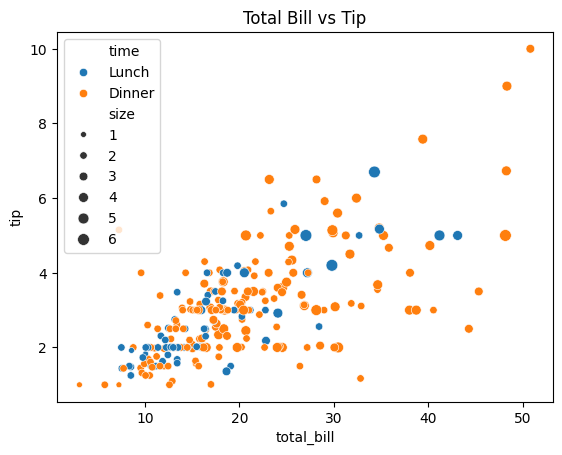

In [5]:
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", size="size")
plt.title("Total Bill vs Tip")
plt.show()

In [6]:
tips["total_bill"].corr(tips["tip"])

np.float64(0.6757341092113641)

لاحظت من الرسم أن البقشيش غالبًا يزيد مع زيادة قيمة الفاتورة، لكن مو في كل الحالات.

حسبت الارتباط وطلعت النتيجة 0.6757

 وهذا يدل على وجود علاقة موجبة بين الفاتورة والبقشيش لكنها مو علاقة ثابتة.

### 5. barplot:

 أتوقع أن يوم الأحد يكون عنده أعلى متوسط للبقشيش، لأنه كان أعلى يوم من ناحية الوسيط في الرسم السابق.

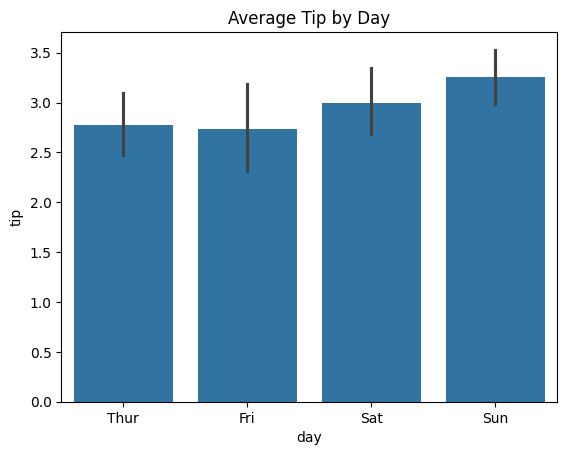

In [7]:
sns.barplot(data=tips, x="day", y="tip")
plt.title("Average Tip by Day")
plt.show()

لاحظت أن يوم الأحد عنده أعلى متوسط للبقشيش بحوالي 3.25 وهذا يتفق مع توقعي.

لكن الخطوط السوداء متداخلة بين الأيام، لذلك ما نقدر نجزم أن الفرق بينها حقيقي.

### 6. heatmap:

أتوقع أن يكون فيه ارتباط بين قيمة الفاتورة والبقشيش، وأعتقد أن عدد الأشخاص له علاقة بقيمة الفاتورة، لأن زيادة عدد الأشخاص ممكن تزيد الطلبات.. لكن مو بالضرورة في كل الحالات.

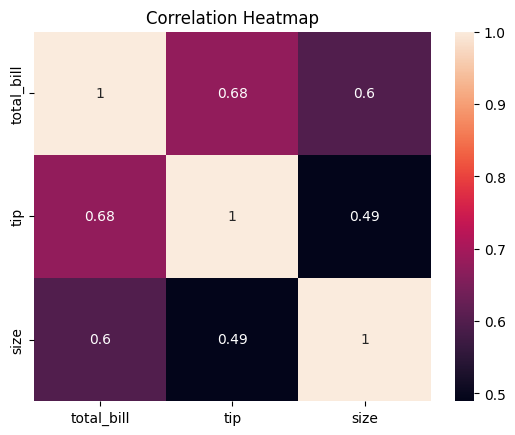

In [8]:
corr = tips[["total_bill", "tip", "size"]].corr()

sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.show()

من الرسم لاحظت أن أقوى ارتباط كان بين قيمة الفاتورة والبقشيش بقيمة 0.68

وبعدها قيمة الفاتورة وعدد الأشخاص بقيمة 0.60

وهذا يوضح أن عدد الأشخاص ممكن
يؤثر على قيمة الفاتورة، لكن ليس دائمًا.

#Task3: القروض بالرسومات

### countplot:

أتوقع أن عدد الطلبات المقبولة يكون أكثر من الطلبات المرفوضة، وهذا نفس الشيء اللي لاحظته في تحليلي السابق للبيانات.

In [9]:
#قراءة الملف
import pandas as pd

loans = pd.read_csv("loan_clean.csv")

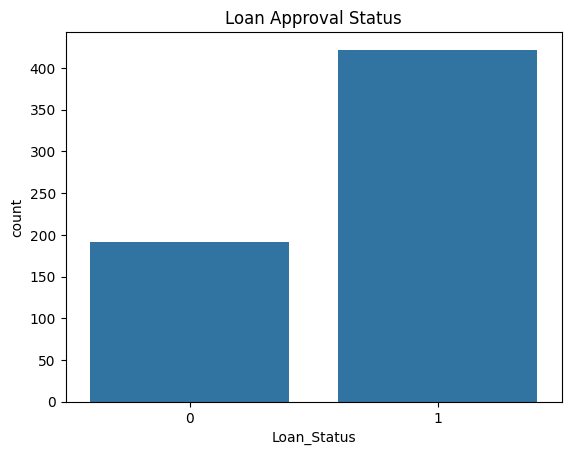

In [10]:
sns.countplot(data=loans, x="Loan_Status")
plt.title("Loan Approval Status")
plt.show()

من الرسم نلاحظ:

- الطلبات المرفوضة (0):

 حوالي 192 طلب.

- الطلبات المقبولة (1):

 حوالي 422 طلب.


يعني تقريبًا 69% من الطلبات مقبولة، و31% مرفوضة.

### barplot:
أتوقع أن الأشخاص اللي عندهم
Credit History جيد

تكون نسبة الموافقة على قروضهم أعلى من الأشخاص اللي ما عندهم سجل ائتماني جيد.

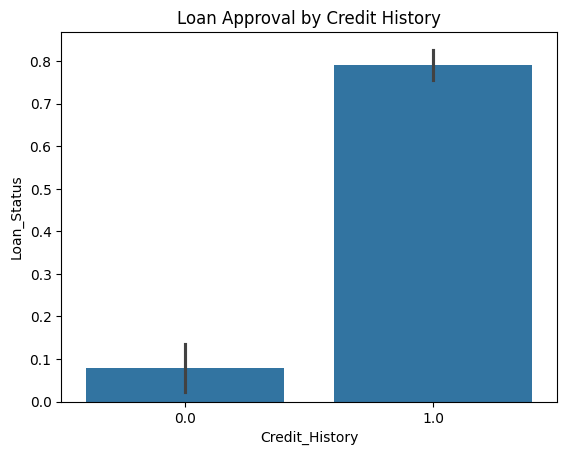

In [11]:
sns.barplot(data=loans, x="Credit_History", y="Loan_Status")
plt.title("Loan Approval by Credit History")
plt.show()

الفرق هنا واضح جدًا

Credit History = 0:

 نسبة الموافقة تقريبًا %8

Credit History = 1:

 نسبة الموافقة تقريبًا %79

 وهذا يوضح أن Credit_History

 له علاقة قوية
 بقرار الموافقة.

### Property_Area:

أتوقع أن تكون نسبة الموافقة أعلى في منطقة معينة مقارنة بباقي المناطق، لكن ما أعرف أي منطقة بالتحديد.

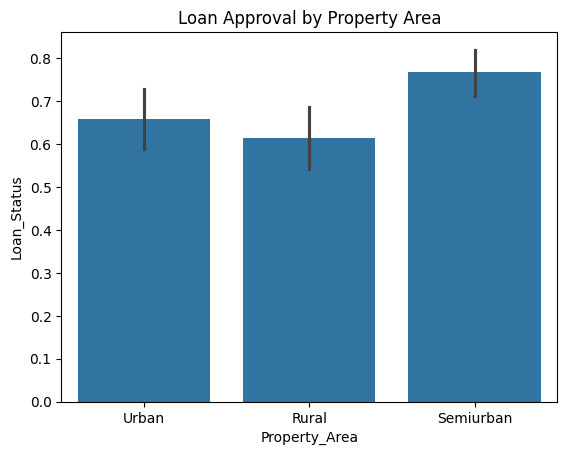

In [12]:
sns.barplot(data=loans, x="Property_Area", y="Loan_Status")
plt.title("Loan Approval by Property Area")
plt.show()

يوجد اختلاف بين المناطق في نسبة الموافقة:

- Semiurban: 77% (الأعلى)
- Urban: 66%.
- Rural: 61% (الأقل)


إذن منطقة Semiurban
عندها أعلى نسبة موافقة

### boxplot:

أتوقع أن الأشخاص اللي تمت الموافقة على قروضهم يكون دخلهم أعلى من الأشخاص اللي تم رفض طلباتهم، لأن الدخل الأعلى ممكن يساعد في سداد القرض.

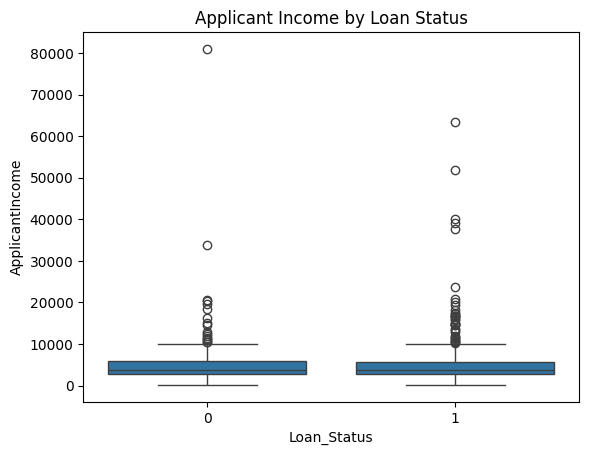

In [13]:
sns.boxplot(data=loans, x="Loan_Status", y="ApplicantIncome")
plt.title("Applicant Income by Loan Status")
plt.show()

لاحظت أن الدخل متقارب بين الأشخاص المقبولين
والمرفوضين، ولايوجد فرق واضح في الوسيط بينهم. وايضًا ظهرت قيم شاذة في المجموعتين.

 لذلك توقعي لم يكن صحيح تمامًا. ويبدو ان الدخل وحده ما يفرق بشكل كبير في قرار الموافقة.

### LoanAmount:

مقارنةً بالرسم السابق أتوقع أن تكون مبالغ القروض متقاربة بين المقبولين والمرفوضين، وما يكون فيه فرق كبير بينهم.

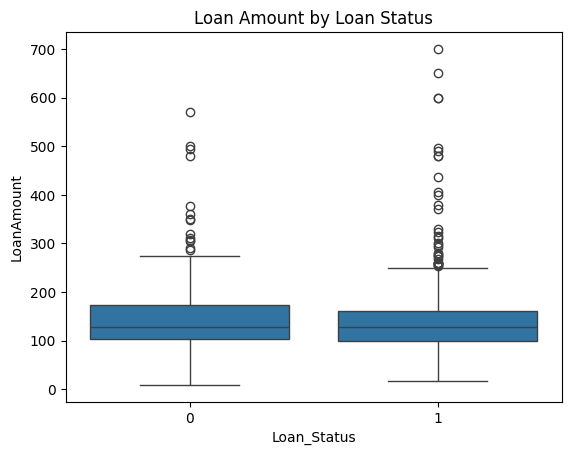

In [14]:
sns.boxplot(data=loans, x="Loan_Status", y="LoanAmount")
plt.title("Loan Amount by Loan Status")
plt.show()


- الوسيط للمقبولين والمرفوضين متقارب جدًا

- الصناديق متداخلة بشكل كبير.

- فيه قيم شاذة في المجموعتين، وبعضها أعلى عند المقبولين.

 بشكل عام ما فيه فرق واضح في مبلغ القرض بين المجموعتين. لذا توقعي صحيح

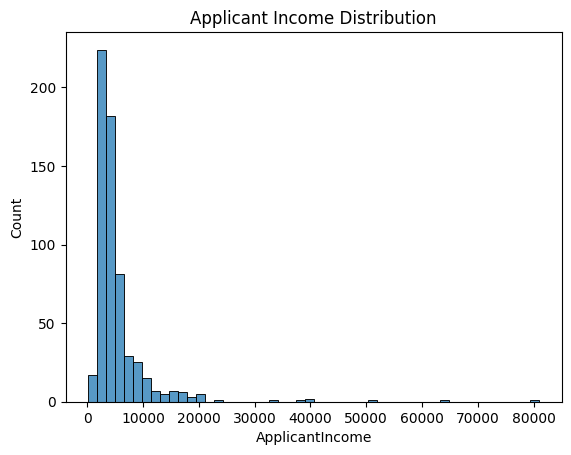

In [16]:
# histplot باستخدام كل الداتا

sns.histplot(data=loans, x="ApplicantIncome")
plt.title("Applicant Income Distribution")
plt.show()

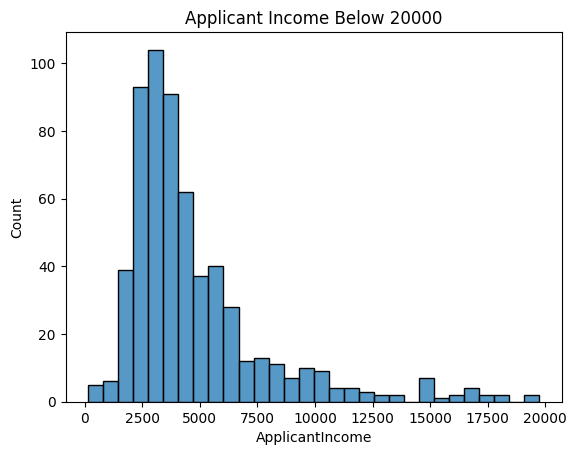

In [17]:
# histplot باستخدام 20,000

sns.histplot(data=loans[loans["ApplicantIncome"] < 20000], x="ApplicantIncome")
plt.title("Applicant Income Below 20000")
plt.show()

لماذا الرسمة الثانية أوضح؟

لأن القيم الكبيرة كانت تضغط الرسم الأول وجعلت أغلب البيانات متجمعة في مساحة صغيرة، لكن عندما حددنا النطاق اصبح توزيع الدخل أوضح.

### heatmap:

أتوقع أن يكون فيه ارتباط قوي بين

Credit_History & Loan_Status

 لأننا لاحظنا سابقًا أن الفرق في نسبة الموافقة كان كبيرًا بين أصحاب السجل الائتماني الجيد وغيرهم.

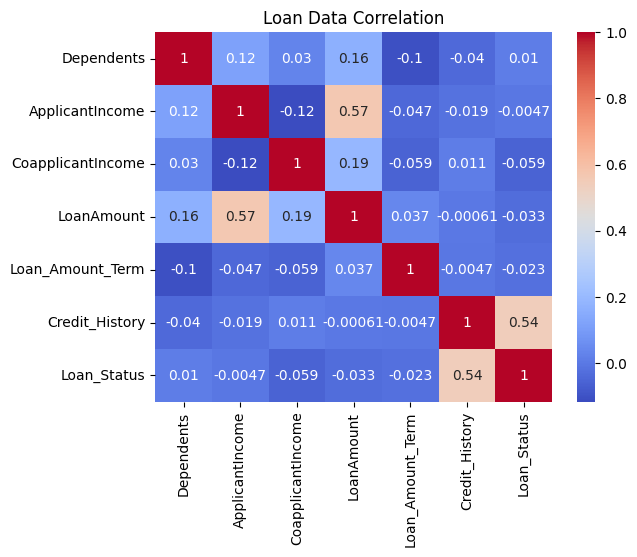

In [18]:
corr = loans.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Loan Data Correlation")
plt.show()

# حساب الارتباط بين الأعمدة الرقمية واظهار القيم

السجل الائتماني هو أكثر عمود مرتبط بقرار الموافقة في البيانات، وهذا يتفق مع التحليل السابق.

### رسمة ام رقم؟

**1. Countplot:**
لاحظت أن الطلبات المقبولة أكثر من المرفوضة، حيث تم قبول 422 طلب تقريبًا مقابل 192 طلب مرفوض.

**2. Credit History:**
واضح أن السجل الائتماني له علاقة قوية بالموافقة، لأن نسبة القبول وصلت إلى 79% لأصحاب السجل الجيد، مقابل 8% فقط لغيرهم.

**3. Property Area:**
منطقة Semiurban كانت الأعلى في نسبة الموافقة بحوالي 77%، مقارنة بـ 66% في Urban و61% في Rural.

**4. Applicant Income:**
الدخل كان متقاربًا بين المقبولين والمرفوضين، والوسيط بينهم متشابه تقريبًا، لذلك ما ظهر فرق واضح.

**5. Loan Amount:**
مبالغ القروض كانت متقاربة أيضًا، والوسيط في المجموعتين حوالي 130.

**6. Histplot:**
أغلب الدخول كانت أقل من 10,000، لكن وجود قيم وصلت إلى أكثر من 80,000 جعل الرسم الأول أقل وضوحًا. بعد تحديد الدخل بأقل من 20,000 صار التوزيع أوضح.

**7. Heatmap:**
أقوى ارتباط مع قرار الموافقة كان Credit_History بقيمة 0.54، بينما كان ارتباط الدخل ومبلغ القرض ضعيفًا جدًا.

### أسئلة التحليل

**أي استنتاج من الأسبوع الماضي أصبح أوضح بالرسمة؟**

استنتاج أن Credit_History من أهم العوامل المرتبطة بقبول القرض، لأن الرسم وضّح الفرق الكبير في نسب الموافقة بين المجموعتين.

**هل كشفت لك رسمة شيئًا لم تلاحظه بالأرقام؟**

نعم، رسم توزيع الدخل وضّح لي تأثير القيم الشاذة على شكل البيانات، وكيف أنها تخلي أغلب القيم متجمعة في مساحة صغيرة وتصعّب قراءتها.

#Task4: سجل التنانين

In [19]:
# Dataset

import numpy as np
import pandas as pd

rng = np.random.default_rng(7)

n = 150

species = rng.choice(["Fire", "Ice", "Storm"], n, p=[0.4, 0.35, 0.25])

base_wing = {"Fire": 14, "Ice": 11, "Storm": 18}
base_heat = {"Fire": 900, "Ice": 80, "Storm": 300}

dragons = pd.DataFrame({
    "dragon_id": [f"D{i:03d}" for i in range(n)],
    "species": species,
    "wingspan_m": [round(base_wing[s] + rng.normal(0, 2), 1) for s in species],
    "fire_temp_c": [round(base_heat[s] + rng.normal(0, 60)) for s in species],
    "age_years": rng.integers(20, 400, n),
})

dragons["weight_t"] = (dragons["wingspan_m"] * 0.6 + rng.normal(0, 0.8, n)).round(1)

dragons.loc[37, "wingspan_m"] = 140.0

dragons.head()

,dragon_id,species,wingspan_m,fire_temp_c,age_years,weight_t
0,D000,Ice,11.0,83,58,6.1
1,D001,Storm,16.6,391,232,9.4
2,D002,Storm,17.3,333,130,10.3
3,D003,Fire,12.9,896,170,6.9
4,D004,Fire,14.0,865,83,8.9


### countplot

أتوقع أن يكون عدد تنانين
Ice

 هو الأقل

 لكن مو متأكدة أي نوع بيكون الأكثر

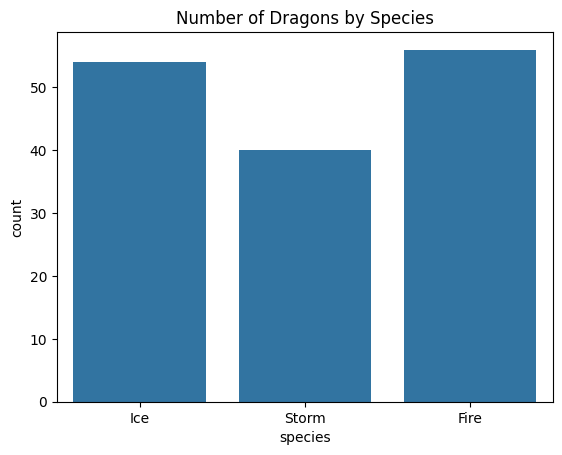

In [20]:
sns.countplot(data=dragons, x="species")
plt.title("Number of Dragons by Species")
plt.show()

لاحظت أن عدد تنانين
Fire وIce متقارب

 Storm هو الأقل بعدد 40 تنين تقريبًا.

توقعت أن Ice يكون الأقل

لكن النتيجة طلعت مختلفة.

### boxplot:

أتوقع أن تنانين
Storm يكون عندها أطول أجنحة بشكل عام

لكن ممكن نلقى تنين عنده طول جناح غير طبيعي مقارنة بباقي التنانين.

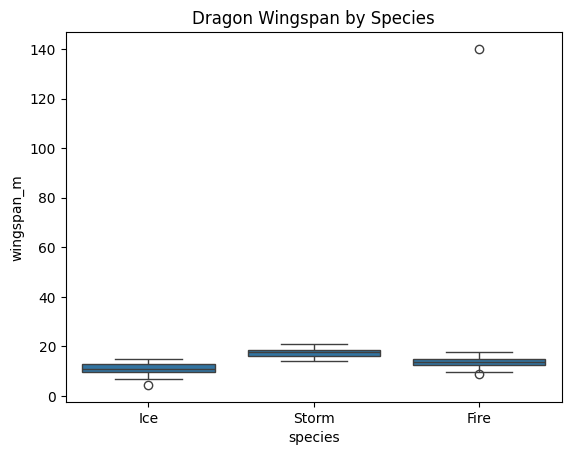

In [21]:
sns.boxplot(data=dragons, x="species", y="wingspan_m")
plt.title("Dragon Wingspan by Species")
plt.show()

تنين من نوع Fire

وصل طول جناحه الى 140 متر

وهذا فرق غير منطقي مقارنةً ببقية الاحجام

In [22]:
# Finding the Unusual Dragon

dragons.loc[37]

,37
dragon_id,D037
species,Fire
wingspan_m,140.0
fire_temp_c,977
age_years,231
weight_t,10.0


وجدت تنين رقم
D037 من نوع Fire،

 وكان طول جناحه 140 متر، وهذا أكبر بكثير من الطبيعي مقارنة بباقي التنانين.

 أعتقد أن فيه خطأ في تسجيل البيانات، ونحتاج نصحح القيمة.

In [23]:
# تصحيح القيمة

fire_median = dragons.loc[
    (dragons["species"] == "Fire") & (dragons.index != 37),
    "wingspan_m" ].median()

dragons.loc[37, "wingspan_m"] = fire_median

print(fire_median)

13.7


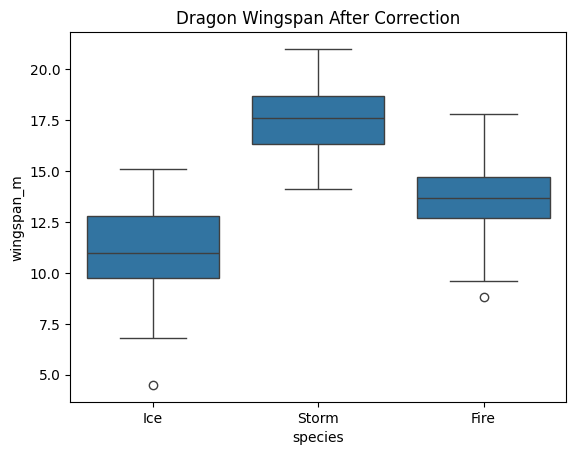

In [24]:
# اعادة الرسم

sns.boxplot(data=dragons, x="species", y="wingspan_m")
plt.title("Dragon Wingspan After Correction")
plt.show()

بعد تصحيح القيمة، اختفت النقطة الغريبة من الرسم.

 لاحظت أن تنانين

Storm عندها أطول أجنحة

بينما Ice

عندها أقصر أجنحة

### scatterplot:

أتوقع أن كل نوع من التنانين بيكون متجمع في مكان مختلف في الرسم، لأن حرارة النار وطول الأجنحة تختلف من نوع للثاني.

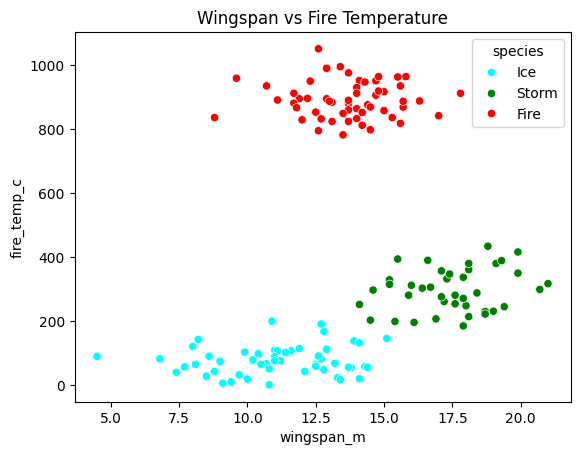

In [28]:
sns.scatterplot(
    data=dragons,
    x="wingspan_m",
    y="fire_temp_c",
    hue="species",
    palette={
        "Ice": "cyan",
        "Storm": "green",
        "Fire": "red"
    }
)

plt.title("Wingspan vs Fire Temperature")
plt.show()

# تحديد الالوان اضافة من عندي

لاحظت أن الأنواع الثلاثة متجمعة في مناطق مختلفة.

Fire = اعلى حرارة

Ice = اقل حرارة

Storm = حرارة متوسطة

### heatmap

أتوقع أن يكون فيه ارتباط قوي بين
wingspan_m وweight_t

لأننا استخدمنا طول الجناح في حساب الوزن من البداية.

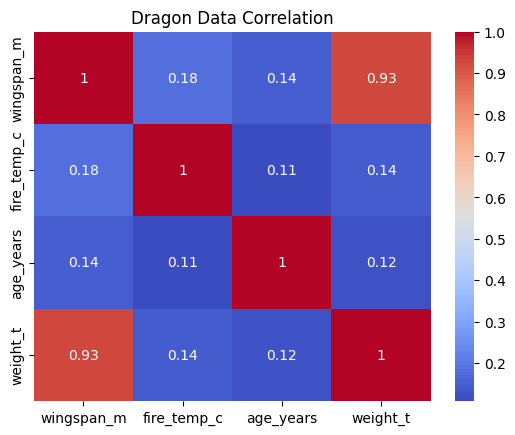

In [29]:
corr = dragons.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Dragon Data Correlation")
plt.show()

أقوى ارتباط كان بين طول الجناح والوزن بقيمة 0.93، وهذا منطقي لأننا حسبنا الوزن اعتمادًا على طول الجناح من البداية.

باقي العلاقات كانت ضعيفة.

### قرار تدفئة القرية:

بعد مقارنة درجات الحرارة بين الأنواع الثلاثة، قررت أرسل تنانين

Storm

 لأن درجة حرارتها تتراوح تقريبًا بين 200 و400 درجة،

 وأشوف أنها ممكن توفر تدفئة مناسبة بدون حرارة زائدة.
___

أما تنانين
Fire

فتتراوح حرارتها تقريبًا بين 800 و1000 درجة

 وممكن تكون حرارتها عالية جدًا على سكان القرية.
____
وبالنسبة لتنانين
Ice

فتتراوح حرارتها غالبًا بين 0 و150 درجة

لذلك ما راح أرسلها أبدًا لأنها الأقل حرارة والأقل مناسبة للتدفئة.